# Raids and displacement

Lead 3 asks whether enforcement removes garimpo or moves it. E12 found that garimpo
cases rose where IBAMA's deterrence collapsed after 2019. This notebook looks at the other
side: IBAMA's garimpo raids, which surge from 2021 (`output/research/mining_economics_leads.md`,
E14).

- **Raids.** IBAMA's garimpo destruction and seizure terms (`enforcement`), dated to the
  day, by the municipality where they took place.
- **Outcome.** SIVEP garimpo cases by infection municipality and notification month
  (`malaria`, to 2024), all, local and incoming, and non-garimpo malaria as the placebo.
- **Episodes.** A municipality's first month with a raid term after 12 months without
  one, 2019–2023.
  - Samples: all raids; large raids (3+ terms in the month); and malaria-visible raids
    (12+ garimpo cases in the 12 months before). SIVEP only sees garimpo where malaria
    is transmitted.
- **Stacked event study,** months −12 to +12 around each raid:
  - *own:* the raided municipality;
  - *neighbours:* each bordering municipality not itself raided in the window.

  Controls are the sample municipalities neither raided in the window nor bordering the
  raided one. Episode × municipality and episode × month FE; SEs clustered by
  municipality.
- **Triple difference.** Raids follow local malaria peaks, so garimpo is also measured
  against non-garimpo malaria in the same municipality-month.
- **Displacement ratio.** Garimpo cases gained by all neighbours per case lost at the
  raid, from the pooled estimates in levels.

Code: `src/analysis/garimpo_raids.py`. Tables go to `output/analysis/garimpo/raids/`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_raids as R

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "raids"
OUT.mkdir(parents=True, exist_ok=True)

panel, raids, adjacency = R.load_inputs()
table = R.episodes(raids)
table["pre_cases"] = R.pre_cases(table, panel)
samples = R.episode_samples(table, panel)
table.to_csv(OUT / "episodes.csv", index=False)
print(panel["mun_id"].nunique(), "sample municipalities,", panel["month"].nunique(), "months")
display(pd.DataFrame({name: [len(part), part["mun_id"].nunique(), int(part["raid_terms"].sum()),
                             part["pre_cases"].median()]
                      for name, part in samples.items()},
                     index=["episodes", "municipalities", "raid terms in the raid month", "median cases before"]))

INFO:src.data.sources.biomes.preprocess:Excluding 2 non-municipality GADM ADM2 polygon(s) (e.g. lagoons).


260 sample municipalities, 84 months


,all raids,large raids (3+ terms),malaria-visible (12+ cases before)
episodes,103,44,43
municipalities,79,42,31
raid terms in the raid month,529,441,274
median cases before,5,10,55


## 1. Raids and cases

In [2]:
yearly = pd.DataFrame({
    "raid terms": raids.groupby(raids["month"].dt.year)["raid_terms"].sum(),
    "raided municipalities": raids.groupby(raids["month"].dt.year)["mun_id"].nunique(),
    "episodes": table.groupby(table["month"].dt.year).size(),
    "garimpo cases (sample)": panel.groupby(panel["month"].dt.year)["inf_garimpo"].sum(),
})
display(yearly.fillna(0).astype(int))
display(table.assign(state=table["mun_id"].str[:2]).pivot_table(
    index="state", columns=table["month"].dt.year, values="mun_id", aggfunc="count", fill_value=0))
display(table["pre_cases"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(1))

,raid terms,raided municipalities,episodes,garimpo cases (sample)
month,,,,
2018,96,29,0,4417
2019,74,19,16,8663
2020,129,29,22,15126
2021,365,34,19,19829
2022,264,37,19,22284
2023,726,48,27,18193
2024,1080,46,0,14609


month,2019,2020,2021,2022,2023
state,,,,,
11,1,2,1,2,2
13,3,1,2,5,12
14,1,3,5,2,1
15,2,8,5,4,4
16,1,2,1,0,1
17,1,1,2,0,2
21,1,0,0,0,2
51,6,5,3,6,3


count     103
mean    145.2
std     497.1
min         0
25%         0
50%         5
75%      41.5
90%     195.2
max      3178
Name: pre_cases, dtype: float64

**Reading the results.** Raids surge late, and many hit places where SIVEP sees little
garimpo.
- *Raid terms (destruction and seizure):* 74–129 a year in 2018–20, 365 (2021), 264
  (2022), 726 (2023) and 1,080 (2024).
- *Episodes:* 103 in 2019–2023, in 79 municipalities. Mato Grosso, Amazonas and Pará
  have 23 each, Roraima 12.
- *Malaria visibility:*
  - A quarter of the raided municipalities had no garimpo case in the 12 months before
    the raid; the median had 5.
  - The 43 malaria-visible episodes (31 municipalities) had a median of 55.
- *Coverage:* SIVEP ends in 2024, so the 2024 surge in raids is outside the episodes.

## 2. At the raid and next door

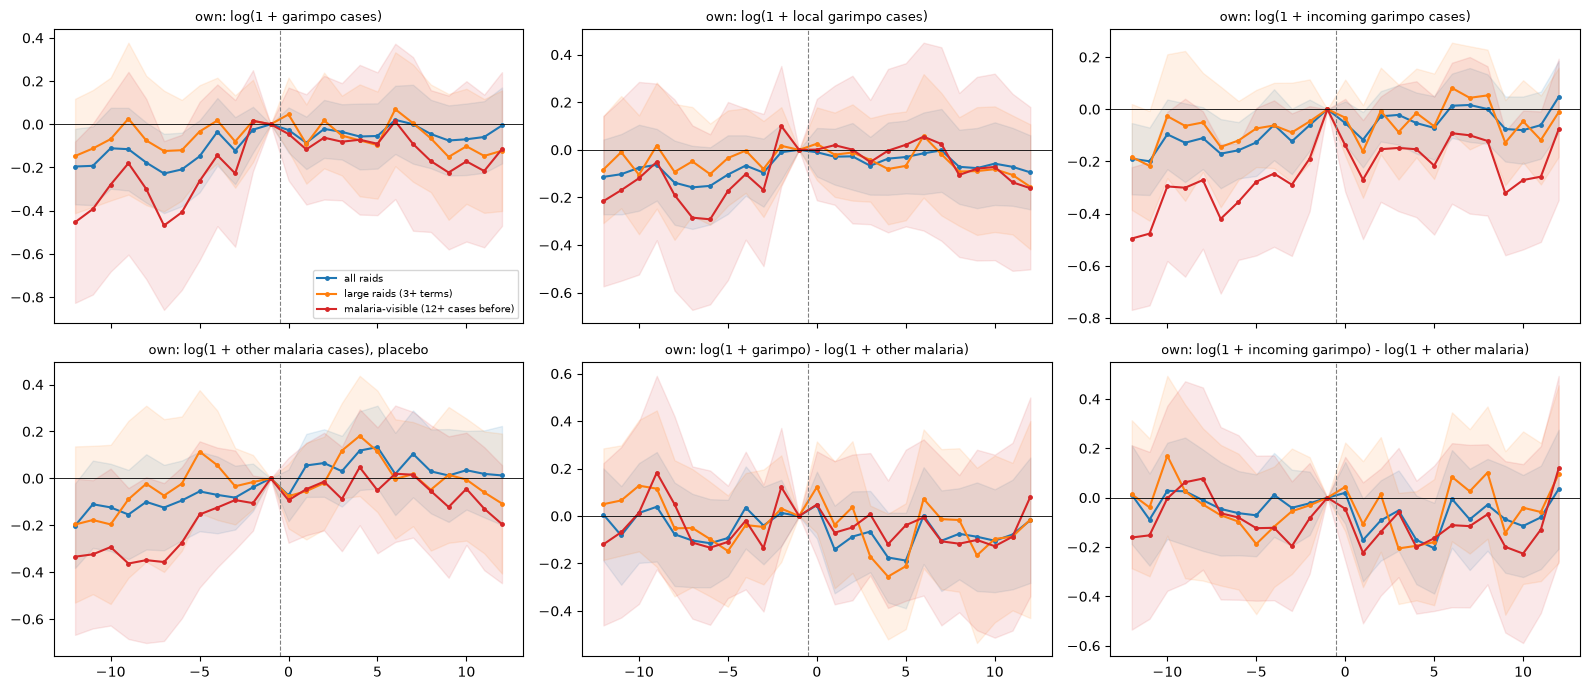

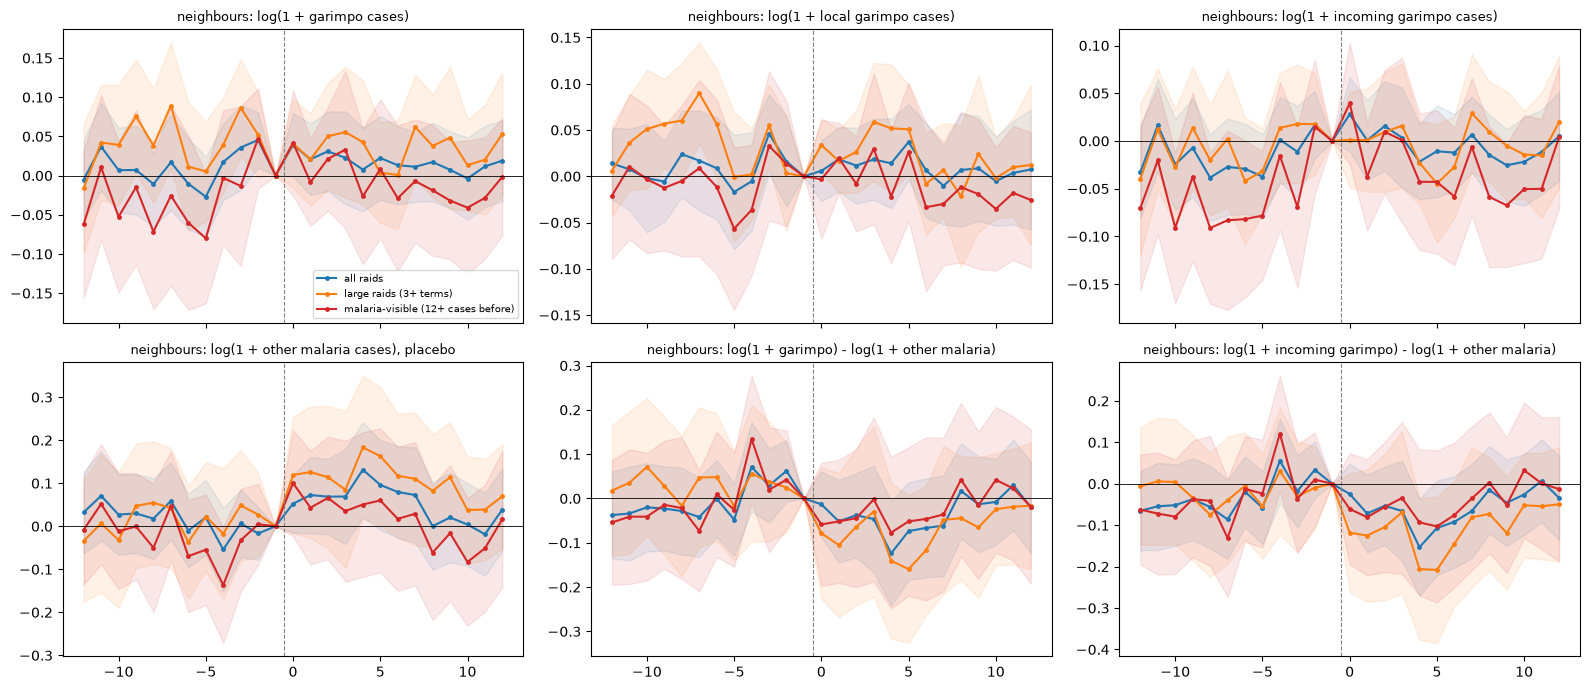

window                                                                -12..-7  -6..-2  -1 (base)   0..2   3..5   6..8  9..12
design     sample                             outcome                                                                       
own        all raids                          log1p_garimpo             -0.17  -0.108          0 -0.045 -0.049 -0.008 -0.052
                                              log1p_garimpo_local      -0.108  -0.085          0 -0.022 -0.045 -0.029 -0.075
                                              log1p_garimpo_incoming   -0.149  -0.106          0 -0.066 -0.049   0.01 -0.042
                                              log1p_other_malaria      -0.136  -0.068          0  0.016  0.094  0.051   0.02
                                              garimpo_vs_other         -0.034   -0.04          0 -0.061 -0.143 -0.059 -0.072
                                              incoming_vs_other        -0.013  -0.037          0 -0.082 -0.143 -0.041 -0.062
           large raids (3+ terms)             log1p_garimpo            -0.083   -0.04          0 -0.009 -0.074  0.003 -0.131
                                              log1p_garimpo_local      -0.053  -0.041          0 -0.002 -0.063 -0.017 -0.108
                                              log1p_garimpo_incoming   -0.114  -0.078          0 -0.067 -0.056  0.059 -0.076
                                              log1p_other_malaria      -0.126   0.019          0  -0.05  0.138 -0.011  -0.04
                                              garimpo_vs_other          0.043   -0.06          0  0.041 -0.212  0.014 -0.091
                                              incoming_vs_other         0.012  -0.098          0 -0.017 -0.194  0.071 -0.036
           malaria-visible (12+ cases before) log1p_garimpo            -0.346  -0.205          0 -0.074 -0.081 -0.083 -0.182
                                              log1p_garimpo_local      -0.172  -0.127          0  0.007 -0.011 -0.008 -0.112
                                              log1p_garimpo_incoming   -0.377  -0.272          0 -0.187 -0.172 -0.104 -0.232
                                              log1p_other_malaria      -0.337   -0.15          0 -0.051 -0.031 -0.006 -0.123
                                              garimpo_vs_other         -0.009  -0.055          0 -0.023  -0.05 -0.076 -0.059
                                              incoming_vs_other         -0.04  -0.121          0 -0.136 -0.142 -0.098 -0.109
neighbours all raids                          log1p_garimpo             0.009   0.012          0   0.03  0.018  0.014  0.009
                                              log1p_garimpo_local       0.009    0.01          0  0.012  0.023  0.001  0.004
                                              log1p_garimpo_incoming   -0.019  -0.012          0  0.015  -0.01 -0.007 -0.013
                                              log1p_other_malaria       0.039  -0.011          0  0.065  0.099  0.051  0.011
                                              garimpo_vs_other         -0.031   0.023          0 -0.034 -0.081 -0.037 -0.003
                                              incoming_vs_other        -0.058  -0.001          0  -0.05 -0.109 -0.058 -0.025
           large raids (3+ terms)             log1p_garimpo             0.045   0.039          0  0.037  0.034  0.034  0.034
                                              log1p_garimpo_local        0.05   0.023          0  0.026  0.054 -0.008  0.011
                                              log1p_garimpo_incoming    -0.01  -0.005          0  0.004 -0.017  0.004 -0.004
                                              log1p_other_malaria       0.014   0.009          0   0.12  0.144  0.103  0.065
                                              garimpo_vs_other          0.031    0.03          0 -0.082  -0.11  -0.07 -0.031
                                              incoming_vs_other        -0.024  -0.014          0 -0.116 -0.161   -0.1 -0.069


In [3]:
OUTCOMES = ["log1p_garimpo", "log1p_garimpo_local", "log1p_garimpo_incoming", "log1p_other_malaria",
            "garimpo_vs_other", "incoming_vs_other"]
stacks = {(design, name): R.stack(panel, part, raids, adjacency, design)
          for design in R.DESIGNS for name, part in samples.items()}
studies = pd.concat([R.event_study(stacked, outcome).assign(design=design, sample=name)
                     for (design, name), stacked in stacks.items() for outcome in OUTCOMES], ignore_index=True)
studies.to_csv(OUT / "event_studies.csv", index=False)

for design in R.DESIGNS:
    fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
    for ax, outcome in zip(axes.ravel(), OUTCOMES):
        for (name, color) in zip(samples, ("C0", "C1", "C3")):
            part = studies[(studies.design == design) & (studies["sample"] == name) & (studies.outcome == outcome)]
            ax.plot(part.rel, part.estimate, marker="o", ms=2.5, color=color, label=name)
            ax.fill_between(part.rel, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color,
                            alpha=0.1)
        ax.axvline(-0.5, color="grey", lw=0.8, ls="--")
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(f"{design}: {R.OUTCOMES[outcome]}", fontsize=9)
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    plt.show()

quarters = studies.assign(window=pd.cut(studies.rel, [-13, -7, -2, -1, 2, 5, 8, 12],
                                         labels=["-12..-7", "-6..-2", "-1 (base)", "0..2", "3..5", "6..8", "9..12"]))
display(quarters.pivot_table(index="window", columns=["design", "sample", "outcome"], values="estimate",
                             observed=True, sort=False).round(3).T)

**Reading the results.** IBAMA raids where malaria is rising, and the raid stops the rise in
garimpo and other malaria alike.
- *At the raid, garimpo cases:*
  - Before: below the month before the raid, by −0.11 to −0.17 in all raids and −0.21 to
    −0.35 in malaria-visible ones. Cases were growing into the raid.
  - After: they stay near that level (between −0.18 and 0). Incoming cases in the visible
    sample are −0.10 to −0.23.
- *The placebo:* non-garimpo malaria follows the same path: −0.34 and −0.15 before in the
  visible sample, −0.12 to −0.01 after.
  - Raids are timed to local malaria peaks, or to the season when both mining and
    transmission rise.
  - So the plain event study cannot separate a raid effect.
- *Against other malaria* (the triple difference):
  - Garimpo is flat before the raid (−0.06 to +0.04).
  - It is slightly lower after: −0.06 to −0.14 in all raids, −0.02 to −0.08 in visible
    ones. Incoming cases are −0.10 to −0.14 in visible ones, but they were also −0.12 in
    months −6 to −2.
- *Next door:*
  - Garimpo cases in bordering municipalities do not move (−0.04 to +0.05).
  - Against other malaria they dip slightly after large raids (−0.07 to −0.16 for incoming
    cases), the opposite of displacement.

## 3. Pooled effects and the displacement ratio

Treated × months 0 to +12 against months −12 to −1.

In [4]:
pooled = pd.DataFrame([{"design": design, "sample": name, **R.pooled(stacked, outcome)}
                       for (design, name), stacked in stacks.items() for outcome in [*OUTCOMES, "inf_garimpo"]])
pooled.to_csv(OUT / "pooled.csv", index=False)
for value in ("estimate", "p"):
    display(pooled.pivot_table(index=["design", "sample"], columns="outcome", values=value, sort=False).round(3))
display(pooled[["design", "sample", "n_episodes", "n_treated_units", "n_obs"]].drop_duplicates(["design", "sample"]))

levels = pooled[pooled.outcome == "inf_garimpo"].set_index(["design", "sample"])
ratios = pd.Series({name: R.displacement_ratio(levels.loc[("own", name)], levels.loc[("neighbours", name)])
                    for name in samples}, name="neighbour cases gained per case lost at the raid")
display(ratios.round(2))

outcome                                        log1p_garimpo  log1p_garimpo_local  log1p_garimpo_incoming  log1p_other_malaria  garimpo_vs_other  incoming_vs_other  inf_garimpo
design     sample                                                                                                                                                               
own        all raids                                    0.09                0.044                   0.081                 0.14            -0.049             -0.058        5.494
           large raids (3+ terms)                         -0               -0.008                   0.052                0.061            -0.061             -0.009        8.081
           malaria-visible (12+ cases before)          0.148                0.101                   0.123                0.173            -0.025              -0.05        12.98
neighbours all raids                                   0.007                0.001                    0.01                0.038             -0.03             -0.028        0.096
           large raids (3+ terms)                     -0.004               -0.015                   0.004                0.094            -0.098              -0.09       -0.509
           malaria-visible (12+ cases before)           0.02               -0.003                   0.024                0.038            -0.017             -0.013        0.227

outcome                                        log1p_garimpo  log1p_garimpo_local  log1p_garimpo_incoming  log1p_other_malaria  garimpo_vs_other  incoming_vs_other  inf_garimpo
design     sample                                                                                                                                                               
own        all raids                                   0.076                0.335                   0.069                0.023             0.344               0.29        0.101
           large raids (3+ terms)                      0.998                0.938                   0.595                  0.6             0.546               0.93         0.27
           malaria-visible (12+ cases before)          0.203                0.345                   0.226                0.129             0.775              0.609        0.104
neighbours all raids                                   0.538                0.923                   0.306                0.258             0.369               0.42        0.686
           large raids (3+ terms)                      0.864                0.343                   0.845                 0.12             0.105              0.149        0.293
           malaria-visible (12+ cases before)          0.379                0.849                   0.204                0.468             0.724              0.799        0.238

,design,sample,n_episodes,n_treated_units,n_obs
0,own,all raids,103,103,531750
7,own,large raids (3+ terms),44,44,225950
14,own,malaria-visible (12+ cases before),43,43,222675
21,neighbours,all raids,94,301,490075
28,neighbours,large raids (3+ terms),40,129,207125
35,neighbours,malaria-visible (12+ cases before),39,144,203975


all raids                            NaN
large raids (3+ terms)               NaN
malaria-visible (12+ cases before)   NaN
Name: neighbour cases gained per case lost at the raid, dtype: float64

**Reading the results.** No measurable effect of a raid on garimpo cases within a year,
at the site or next door.
- *Own municipality, pooled post-raid against pre-raid:*
  - garimpo cases +0.09 (p 0.08) in all raids and +0.15 (p 0.20) in visible ones, which
    is the pre-raid rise;
  - against other malaria −0.05 (p 0.34) and −0.03 (p 0.78).
- *Neighbours:*
  - garimpo cases −0.004 to +0.02 (p ≥ 0.38);
  - against other malaria −0.02 to −0.10 (p ≥ 0.10).
- *Displacement ratio:* not defined, since no raid sample loses cases at the site in
  levels (+5 to +13 cases per municipality-month, p ≥ 0.10).
- *Power:* about 100 episodes (43 visible), each a single municipality-month raid
  against monthly counts that are mostly small. Against other malaria, the 95% interval
  reaches about −0.15 in all raids and −0.20 in visible ones, so a fall of that size
  cannot be ruled out.
- *What it says:* within a year, a raid of the size IBAMA ran in 2019–2023 does not
  measurably reduce garimpo malaria where it happens. Crews do not show up in bordering
  municipalities either.
  - They may move farther or leave the region.
  - Raids may stop operations without stopping infection among those who stay.
  - SIVEP may simply be too coarse for one raid.